## 0. Importing PyTorch and setting up device agnostic code

In [137]:
%pip install tqdm.auto

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement tqdm.auto (from versions: none)
ERROR: No matching distribution found for tqdm.auto


In [2]:
import torch 
from torch import nn 
import matplotlib.pyplot as plt

# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [3]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [4]:
from pathlib import Path

data_path = Path("data")
image_path = data_path/ "applepie_fries_icecream_20_percent"

print(image_path, "exists:", image_path.exists())

data\applepie_fries_icecream_20_percent exists: True


## 1. Becoming one with the data and we have already downloaded the data from Food 101 dataset and created our custom dataset from this script `04_custom_data_creation_applepie_fries_icecream.ipynb` so now we have three classes `apple_pie`, `french_fries`, `ice_cream`

In [5]:
# lets vizualize the images
import random 
from PIL import Image

# Set seed
random.seed(21)

image_path_list = list(image_path.glob("*/*/*.jpg"))
image_path_list

[WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/1011328.jpg'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/101251.jpg'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/1047447.jpg'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/1375404.jpg'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/1398774.jpg'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/1444702.jpg'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/1617515.jpg'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/168971.jpg'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/1771374.jpg'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/1847621.jpg'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/2189388.jpg'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test/apple_pie/2206649.j

data\applepie_fries_icecream_20_percent\train\ice_cream\2085894.jpg
ice_cream
Random image path:data\applepie_fries_icecream_20_percent\train\ice_cream\2085894.jpg
Image class:ice_cream
Image height:512
Image width: 512


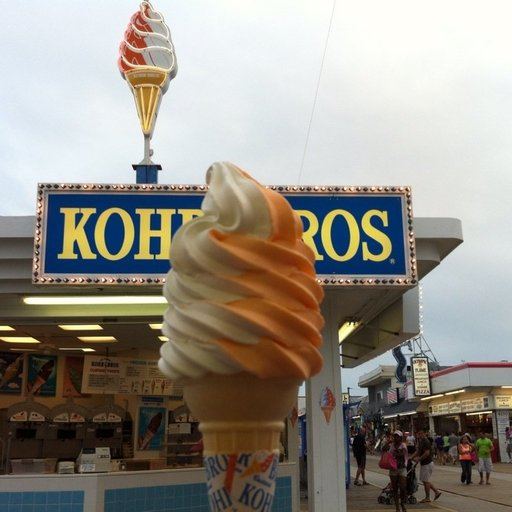

In [48]:
# Pick a random image path and plot it 
random_image_path = random.choice(image_path_list)
print(random_image_path)

#Get the image class 
image_class = random_image_path.parent.stem
print(image_class)

# Open image 
img = Image.open(random_image_path)

# Print metadata
print(f"Random image path:{random_image_path}")
print(f"Image class:{image_class}")
print(f"Image height:{img.height}")
print(f"Image width: {img.width}")
img

## 2. Transforming the data 

#### Before we can use the data with PyTorch:
* Turn your data into `tensors` (in our case the numerical representation of our images).
* Turn it into a `torch.utils.data.Dataset` and subsequently a `torch.utils.data.DataLoader` and we will call these `Dataset` and `DataLoader`

In [49]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [50]:
train_dir = image_path / "train"
test_dir = image_path / "test"

### 2.1 Transforming the data with `torchvision.transforms`

In [51]:
data_transform = transforms.Compose([
    #Resize the original image
    transforms.Resize(size=(64, 64)),
    #Flip the images randomly on the horizontal 
    transforms.RandomHorizontalFlip(p=0.5),
    #turn the image into torch.tensor
    transforms.ToTensor()
])

In [52]:
data_transform(img).shape

torch.Size([3, 64, 64])

In [ ]:
def plot_transformed_images(image_paths, transform, n=3, seed=21):
    if seed:
        random.seed(seed)
    random_image_paths = random.sample(image_paths, k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(nrows=1, ncols=2)
            ax[0].imshow(f)
            ax[0].set_title(f"Original\nSize: {f.size}")
            ax[0].axis(False)

            #transform and plot target image 
            transformed_image = transform(f).permute(1, 2, 0) # (H, W, C) 
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed\nShape:{transformed_image.shape}")
            ax[1].axis(False)

            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=18)

plot_transformed_images(image_paths=image_path_list,
                      transform=data_transform,
                      n=3,
                      seed=21)

## 3. Option 1: Loading Image using `ImageFolder` from PyTorch 

* Link for extra information - https://docs.pytorch.org/vision/main/generated/torchvision.datasets.ImageFolder.html

In [53]:
# Use imagefolder toc create datasets
from torchvision import datasets
train_data = datasets.ImageFolder(root=train_dir,
                                 transform=data_transform,      # this is for data transform that is the image
                                 target_transform=None)         # this is for the image class(labels) transform

In [54]:
test_data = datasets.ImageFolder(root=test_dir,
                                transform= data_transform)

In [55]:
train_data, test_data

(Dataset ImageFolder
     Number of datapoints: 451
     Root location: data\applepie_fries_icecream_20_percent\train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 150
     Root location: data\applepie_fries_icecream_20_percent\test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [56]:
# Get class names
class_names = train_data.classes
class_names

['apple_pie', 'french_fries', 'ice_cream']

In [57]:
class_dict = train_data.class_to_idx
class_dict

{'apple_pie': 0, 'french_fries': 1, 'ice_cream': 2}

In [58]:
img, label = train_data[0][0], train_data[0][1]
print(f"Image tensor:\n{img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")

Image tensor:
tensor([[[0.0784, 0.0706, 0.0784,  ..., 0.0314, 0.0275, 0.0235],
         [0.0784, 0.0745, 0.0824,  ..., 0.0314, 0.0275, 0.0275],
         [0.0824, 0.0824, 0.0824,  ..., 0.0314, 0.0275, 0.0275],
         ...,
         [0.0510, 0.0549, 0.0588,  ..., 0.0824, 0.0902, 0.0667],
         [0.0510, 0.0549, 0.0549,  ..., 0.0824, 0.0902, 0.0745],
         [0.0510, 0.0510, 0.0588,  ..., 0.0941, 0.0863, 0.0863]],

        [[0.0588, 0.0510, 0.0588,  ..., 0.0235, 0.0196, 0.0157],
         [0.0588, 0.0549, 0.0627,  ..., 0.0235, 0.0196, 0.0196],
         [0.0549, 0.0588, 0.0588,  ..., 0.0235, 0.0196, 0.0196],
         ...,
         [0.0353, 0.0392, 0.0431,  ..., 0.0588, 0.0549, 0.0431],
         [0.0353, 0.0392, 0.0392,  ..., 0.0627, 0.0588, 0.0549],
         [0.0353, 0.0353, 0.0431,  ..., 0.0745, 0.0588, 0.0588]],

        [[0.0784, 0.0667, 0.0706,  ..., 0.0353, 0.0235, 0.0196],
         [0.0784, 0.0706, 0.0745,  ..., 0.0353, 0.0235, 0.0235],
         [0.0824, 0.0745, 0.0706,  ..., 0.02

### 3.1 Turn the data into `DataLoader`

* A **`DataLoader`** is going to help us turn our Datasets into iterables and we can customzie the batch size so our model can see batch size images at a time 

In [67]:
import os 
os.cpu_count()  # gives us the num workers 

32

In [71]:
#Turn images into Dataloader
from torch.utils.data import DataLoader

BATCH_SIZE = 32
train_dataloader = DataLoader(dataset=train_data,
                             batch_size=BATCH_SIZE,
                             num_workers=4,
                             shuffle=True)
test_dataloader = DataLoader(dataset=test_data,
                            batch_size=BATCH_SIZE,
                            num_workers=4,
                            shuffle=False)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x2a2d62d7240>,
 <torch.utils.data.dataloader.DataLoader at 0x2a2d62d7350>)

In [75]:
len(train_dataloader), len(test_dataloader)

(15, 5)

## 4. Option 2: Loading Image Data with Custom `Dataset`
1. want to able to load image from file
2. Want to able to get class names from the Dataset
3. Want to be able to get classes as dictionary from the Dataset  

In [78]:
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from typing import Tuple, Dict, List
import pathlib
from pathlib import Path

In [79]:
# Instance of torchvision.datasets.ImageFolder()
train_data.classes, train_data.class_to_idx

(['apple_pie', 'french_fries', 'ice_cream'],
 {'apple_pie': 0, 'french_fries': 1, 'ice_cream': 2})

We want to create something like this which we will us class name and it will also give the idx 

### 4.1 Creating a helper function to get class names 
#### We want a function to :
* Get the class names using `os.scandir()` to traverse a target directory
* Raise an error if the class name aren't found
* Turn the class names into dict and a listand return them 

In [80]:
target_directory = train_dir
print(f"Target_directory: {target_directory}")

# get the class names from the target directory
class_names_found = sorted([entry.name for entry in list(os.scandir(target_directory))])
class_names_found

Target_directory: data\applepie_fries_icecream_20_percent\train


['apple_pie', 'french_fries', 'ice_cream']

In [81]:
# Make function to find classes in target directory 
def find_classes(directory: str) -> Tuple[List[str], Dict[str, int]]:
     #1. Get the class names by scanning the target directory
        classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())
    
        # 2. Raise an error if class names not found
        if not classes:
            raise FileNotFoundError(f"Couldn't find any classes in {directory}.")
        
        # 3. Create a dictionary of index labels (computers prefer numerical rather than string labels)
        class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
        return classes, class_to_idx

        """
            Finds the class folder names in a target directory.
        
        Assumes target directory is in standard image classification format.
    
        Args:
            directory (str): target directory to load classnames from.
    
        Returns:
            Tuple[List[str], Dict[str, int]]: (list_of_class_names, dict(class_name: idx...))
        
        Example:
            find_classes("food_images/train")
            >>> (["class_1", "class_2"], {"class_1": 0, ...})
        """

In [94]:
find_classes(train_dir)

(['apple_pie', 'french_fries', 'ice_cream'],
 {'apple_pie': 0, 'french_fries': 1, 'ice_cream': 2})

### 4.2 Create a custom `Dataset` to replicate `ImageFolder`

* To create our own custom dataset like **`ImageFolder`** from PyTorch we want to:
   1. Subclass `torch.utils.data.Dataset`
   2. Init our subclass with a target directory (the directory we would like to get data from) as well as transform
   3. Create several attributes:
      * paths -paths of our images
      * transform - the transform we would like to use
      * classes - a list of target classes
      * classes_to_idx - a dict of target classes(labels) mapped to integer label
   4. Create a function to `load_images` this function will open an image
   5. Overwrite __len()__ method to return the length of the dataset
   6. Overwrite the __getitem()__ method to return a given sample when passed an index 

In [95]:
# Write a custom dataset class
from torch.utils.data import Dataset

# 1. Subclass torch utils data
class ImageFolderCustom(Dataset):
    #2. Initialize the subclass
    def __init__(self, targ_dir:str, transform=None):
        # 3. Create several attributes
        self.paths = list(pathlib.Path(targ_dir).glob("*/*.jpg"))
        # setup transform
        self.transform = transform
        # Create classes and classes to idx
        self.classes = self.classes_to_idx = find_classes(targ_dir)

    # 4. Create function to load image
    def load_image(self, index):
        image_path = self.paths[index]
        return Image.open(image_path)

    # 5. Overwrite __len()__
    def __len__(self):
        return len(self.paths)

    # 6. Overwrite __getitem()__
    def __getitem__(self, index):
        img = self.load_image(index)
        class_name = self.paths[index].parent.name   # expects path in format: data/class_name/image.jpg
        class_idx = self.classes_to_idx[class_name]

        #Transform if necessary
        if self.transform:
            return self.transform(img), class_idx
        else:
            return img, class_to_idx 

In [96]:
# Create a transform
train_transforms = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

test_transforms = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor()
])

In [97]:
train_data_custom = ImageFolderCustom(targ_dir=train_dir, transform=train_transforms)

In [98]:
test_data_custom = ImageFolderCustom(targ_dir=test_dir, transform=test_transforms)

In [99]:
train_data_custom, test_data_custom

(<__main__.ImageFolderCustom at 0x2a2d6397e00>,
 <__main__.ImageFolderCustom at 0x2a2d64756d0>)

In [100]:
train_data

Dataset ImageFolder
    Number of datapoints: 451
    Root location: data\applepie_fries_icecream_20_percent\train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )

In [101]:
len(train_data), len(train_data_custom)

(451, 450)

In [102]:
train_data_custom.classes

(['apple_pie', 'french_fries', 'ice_cream'],
 {'apple_pie': 0, 'french_fries': 1, 'ice_cream': 2})

### 4.3 Turn custom loaded images into Dataloaders

In [103]:
from torch.utils.data import DataLoader
train_dataloader_custom = DataLoader(dataset=train_data_custom, # use custom created train Dataset
                                     batch_size=32, # how many samples per batch?
                                     num_workers=4, # how many subprocesses to use for data loading? (higher = more)
                                     shuffle=True) # shuffle the data

test_dataloader_custom = DataLoader(dataset=test_data_custom, # use custom created test Dataset
                                    batch_size=32, 
                                    num_workers=4, 
                                    shuffle=False) # don't usually need to shuffle testing data

train_dataloader_custom, test_dataloader_custom

(<torch.utils.data.dataloader.DataLoader at 0x2a2d62d7790>,
 <torch.utils.data.dataloader.DataLoader at 0x2a2d62d69c0>)

## 5. Data Augmentation 

In [104]:
from torchvision import transforms

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.TrivialAugmentWide(num_magnitude_bins=25), # how intense 
    transforms.ToTensor() 
])

# Don't need to perform augmentation on the test data
test_transforms = transforms.Compose([
    transforms.Resize((224, 224)), 
    transforms.ToTensor()
])



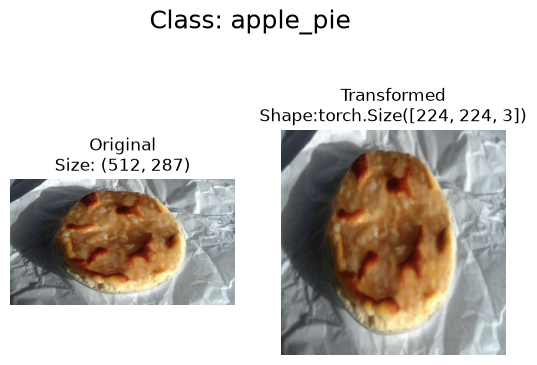

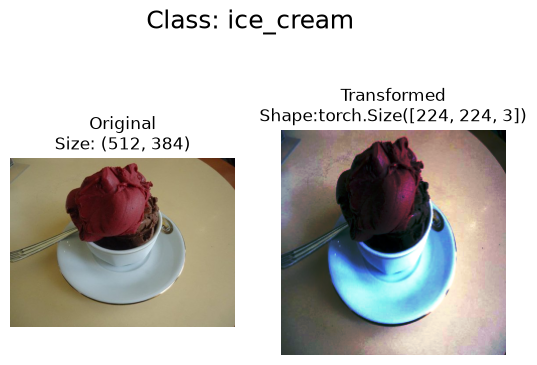

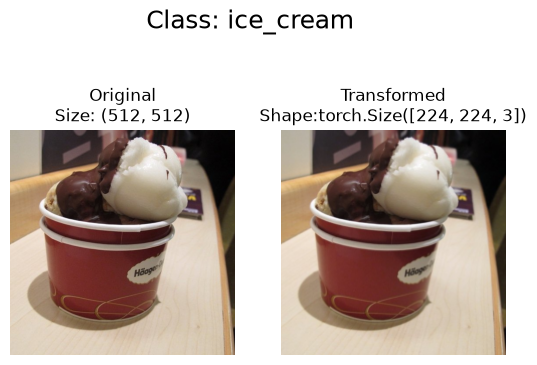

In [105]:
# Get all image paths
image_path_list = list(image_path.glob("*/*/*.jpg"))

# Plot random images
plot_transformed_images(
    image_paths=image_path_list,
    transform=train_transforms,
    n=3,
    seed=None
)

## 6. Model 0: TinyVGG model without data augmentation

In [106]:
# Creating transforms and loading model for Model 0
simple_transforms = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.ToTensor()
])

In [107]:
from torchvision import datasets
train_data_simple = datasets.ImageFolder(root=train_dir,
                                 transform=simple_transforms,      # this is for data transform that is the image
                                 target_transform=None)         # this is for the image class(labels) transform 

test_data_simple = datasets.ImageFolder(root=test_dir,
                                       transform=simple_transforms)

# Turn the data into Dataloaders
BATCH_SIZE=32
train_dataloader_simple = DataLoader(dataset=train_data_simple,
                                    batch_size=BATCH_SIZE,
                                    num_workers=4,
                                    shuffle=True)
test_dataloader_simple = DataLoader(dataset=test_data_simple,
                                   batch_size=BATCH_SIZE,
                                   num_workers=4,
                                   shuffle=False)

### 6.1 Create TinyVGG 
#### We have already created this in computer vision 

In [155]:
class TinyVGG(nn.Module):
    def __init__(self, input_shape, hidden_units, output_shape):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                    out_channels=hidden_units,
                     kernel_size=3,
                     stride=1,
                     padding=0),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                     out_channels=hidden_units,
                     kernel_size=3,
                     stride=1,
                     padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                        stride=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,
                     out_channels=hidden_units,
                     kernel_size=3,
                     stride=1,
                     padding=0),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                     out_channels=hidden_units,
                     kernel_size=3,
                     stride=1,
                     padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                        stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*13*13,
                     out_features=output_shape)
        )
    def forward(self,x):
        return self.classifier(self.conv_block_2(self.conv_block_1(x)))
        

In [156]:
torch.manual_seed(21)
model_0 = TinyVGG(input_shape=3, hidden_units=10, output_shape=len(class_names)).to(device)

In [157]:
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1690, out_features=3, bias=True)
  )
)

In [158]:
model_0.state_dict()

OrderedDict([('conv_block_1.0.weight',
              tensor([[[[-0.0102,  0.0437, -0.1878],
                        [-0.1772,  0.0259, -0.0948],
                        [ 0.0130,  0.0421,  0.0832]],
              
                       [[ 0.0401,  0.1917, -0.1368],
                        [-0.0456,  0.0478,  0.1775],
                        [-0.1438,  0.1452, -0.1793]],
              
                       [[-0.0387,  0.0840,  0.1194],
                        [ 0.0004, -0.1711, -0.1029],
                        [-0.1503,  0.0025,  0.0385]]],
              
              
                      [[[-0.1644,  0.1763,  0.1873],
                        [-0.1512,  0.0212, -0.0810],
                        [-0.1144, -0.0215, -0.1798]],
              
                       [[-0.0456,  0.1409, -0.0508],
                        [ 0.0048,  0.0508,  0.1511],
                        [ 0.0463, -0.1173, -0.0803]],
              
                       [[-0.1251,  0.0579,  0.1847],
                 

### 6.2 Try a forward pass on a single image to check the shape and if our forward pass is working properly 

In [159]:
image_batch, label_batch = next(iter(train_dataloader_simple))
image_batch.shape, label_batch.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

In [160]:
# try a forward pass 
model_0(image_batch.to(device))

tensor([[0.0111, 0.0180, 0.0317],
        [0.0113, 0.0118, 0.0356],
        [0.0129, 0.0161, 0.0276],
        [0.0085, 0.0143, 0.0284],
        [0.0134, 0.0110, 0.0323],
        [0.0100, 0.0183, 0.0286],
        [0.0148, 0.0104, 0.0357],
        [0.0076, 0.0139, 0.0333],
        [0.0080, 0.0163, 0.0272],
        [0.0131, 0.0187, 0.0312],
        [0.0054, 0.0121, 0.0295],
        [0.0112, 0.0143, 0.0315],
        [0.0098, 0.0178, 0.0325],
        [0.0061, 0.0143, 0.0316],
        [0.0091, 0.0167, 0.0303],
        [0.0094, 0.0149, 0.0264],
        [0.0134, 0.0140, 0.0325],
        [0.0081, 0.0129, 0.0356],
        [0.0110, 0.0172, 0.0352],
        [0.0116, 0.0030, 0.0297],
        [0.0164, 0.0177, 0.0293],
        [0.0089, 0.0167, 0.0309],
        [0.0118, 0.0158, 0.0296],
        [0.0102, 0.0124, 0.0339],
        [0.0122, 0.0171, 0.0317],
        [0.0152, 0.0111, 0.0328],
        [0.0151, 0.0114, 0.0274],
        [0.0168, 0.0161, 0.0337],
        [0.0137, 0.0135, 0.0358],
        [0.003

### 6.3 Use **`torchinfo`** to get an idea of the shapes going through the model

In [161]:
%pip install torchinfo

Note: you may need to restart the kernel to use updated packages.


In [162]:
from torchinfo import summary
summary(model_0, input_size=[1,3,64,64])

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 10, 30, 30]           --
│    └─Conv2d: 2-1                       [1, 10, 62, 62]           280
│    └─ReLU: 2-2                         [1, 10, 62, 62]           --
│    └─Conv2d: 2-3                       [1, 10, 60, 60]           910
│    └─ReLU: 2-4                         [1, 10, 60, 60]           --
│    └─MaxPool2d: 2-5                    [1, 10, 30, 30]           --
├─Sequential: 1-2                        [1, 10, 13, 13]           --
│    └─Conv2d: 2-6                       [1, 10, 28, 28]           910
│    └─ReLU: 2-7                         [1, 10, 28, 28]           --
│    └─Conv2d: 2-8                       [1, 10, 26, 26]           910
│    └─ReLU: 2-9                         [1, 10, 26, 26]           --
│    └─MaxPool2d: 2-10                   [1, 10, 13, 13]           --
├─Sequentia

### 6.4 Create train and test step loop functions `train_step()` and `test_step()`

In [163]:
# Create train step 
def train_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              optimizer: torch.optim.Optimizer):
    model.train()

    # Set up train loss and train acc
    train_loss , train_acc = 0,0

    #loop through our batched data
    for batch,(X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Forward pass
        y_pred = model(X)

        #Calculate the loss
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        #Optimizer
        optimizer.zero_grad()

        #Backprop
        loss.backward()

        # optimizer step
        optimizer.step()

        #Calculate accuracy metric
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class==y).sum().item()/len(y_pred)

    #Adjust metric to get average loss and accuracy per batch
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc

In [175]:
#create test step
def test_step(dataloader: torch.utils.data.DataLoader,
              model: torch.nn.Module,
              loss_fn: torch.nn.Module,
              device=device):
    test_loss, test_acc = 0, 0
    model.to(device)
    model.eval() # put model in eval mode
    # Turn on inference context manager
    with torch.inference_mode(): 
        #loop through our batched data
        for batch,(X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)
 
            # 1. Forward pass
            test_pred_logits = model(X)
            
            # 2. Calculate loss and accuracy
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()

            #accuracy
            test_pred_labels= test_pred_logits.argmax(dim=1)
            test_acc += (test_pred_labels==y).sum().item()/len(test_pred_labels)

    # Adjust metrics and print out
    test_loss /= len(dataloader)
    test_acc /= len(dataloader)
    return test_loss, test_acc


### 6.5 Creating a **`train()`** function to combine train_step() and test_step()

In [178]:
from tqdm.auto import tqdm

# 1. Create a train function that takes in various model parameters + optimizers + dataloader + loss function
def train(model: torch.nn.Module,
         train_dataloader: torch.utils.data.DataLoader,
         test_dataloader: torch.utils.data.DataLoader,
         optimzier: torch.optim.Optimizer,
         loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
         epochs: int=5,
         device=device):

    #2. Create empty results dictionary
    results = {"train_loss": [],
              "train_acc": [],
              "test_loss":[],
              "test_acc":[]}

    #3.Loop through training and testing steps for a number of epochs
    for epoch in tqdm (range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer)
        test_loss, test_acc = test_step(model=model,
                                       dataloader=test_dataloader,
                                       loss_fn=loss_fn)
        
        # 4. Print out what's happening
        print(
            f"Epoch: {epoch+1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

        # 5. Update results dictionary
        # Ensure all data is moved to CPU and converted to float for storage
        results["train_loss"].append(train_loss.item() if isinstance(train_loss, torch.Tensor) else train_loss)
        results["train_acc"].append(train_acc.item() if isinstance(train_acc, torch.Tensor) else train_acc)
        results["test_loss"].append(test_loss.item() if isinstance(test_loss, torch.Tensor) else test_loss)
        results["test_acc"].append(test_acc.item() if isinstance(test_acc, torch.Tensor) else test_acc)

    # 6. Return the filled results at the end of the epochs
    return results

### 6.6 Train and evaluate model 0 

In [180]:
torch.manual_seed(21)
torch.cuda.manual_seed(21)

# Set number of epochs 
NUM_EPOCHS = 20

# Recreate an instance of TinyVGG
model_0 = TinyVGG(input_shape=3,
                 hidden_units=10,
                 output_shape=len(train_data.classes)).to(device)

# Setup loss function
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(),
                            lr=0.001)

model_0_results = train(model=model_0,
                       train_dataloader=train_dataloader_simple,
                       test_dataloader=test_dataloader_simple,
                       optimzier=optimizer,
                       loss_fn=loss_fn,
                       epochs=NUM_EPOCHS)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0935 | train_acc: 0.3618 | test_loss: 1.0773 | test_acc: 0.3722
Epoch: 2 | train_loss: 1.0101 | train_acc: 0.4958 | test_loss: 0.9803 | test_acc: 0.5523
Epoch: 3 | train_loss: 0.9256 | train_acc: 0.5424 | test_loss: 0.9499 | test_acc: 0.5256
Epoch: 4 | train_loss: 0.8848 | train_acc: 0.5896 | test_loss: 1.0085 | test_acc: 0.5477
Epoch: 5 | train_loss: 0.9430 | train_acc: 0.5424 | test_loss: 0.9611 | test_acc: 0.5801
Epoch: 6 | train_loss: 0.8884 | train_acc: 0.5590 | test_loss: 0.9155 | test_acc: 0.5932
Epoch: 7 | train_loss: 0.9517 | train_acc: 0.5743 | test_loss: 0.9210 | test_acc: 0.5875
Epoch: 8 | train_loss: 0.9262 | train_acc: 0.5743 | test_loss: 0.9385 | test_acc: 0.5716
Epoch: 9 | train_loss: 0.9098 | train_acc: 0.5882 | test_loss: 0.9502 | test_acc: 0.5767
Epoch: 10 | train_loss: 0.9520 | train_acc: 0.5118 | test_loss: 0.9524 | test_acc: 0.6011
Epoch: 11 | train_loss: 0.8696 | train_acc: 0.5618 | test_loss: 0.9160 | test_acc: 0.5778
Epoch: 12 | train_l

In [181]:
model_0_results

{'train_loss': [1.0935448010762532,
  1.0101103941599527,
  0.9255923271179199,
  0.8848064998785655,
  0.9429816524187724,
  0.8884090145428976,
  0.9517021457354228,
  0.9262418786684672,
  0.90982612768809,
  0.9519963343938191,
  0.8695769588152568,
  0.8537007013956706,
  0.8649195988972982,
  0.8389027456442515,
  0.8575886766115824,
  0.9005666931470235,
  0.8386412501335144,
  0.8364202459653218,
  0.8233494361241659,
  0.8656261126200359],
 'train_acc': [0.36180555555555555,
  0.49583333333333335,
  0.5423611111111111,
  0.5895833333333333,
  0.5423611111111111,
  0.5590277777777778,
  0.5743055555555556,
  0.5743055555555556,
  0.5881944444444444,
  0.5118055555555555,
  0.5618055555555556,
  0.6215277777777778,
  0.5777777777777777,
  0.61875,
  0.5951388888888889,
  0.5847222222222223,
  0.617361111111111,
  0.6194444444444444,
  0.617361111111111,
  0.5840277777777777],
 'test_loss': [1.0772641181945801,
  0.9803027272224426,
  0.9499015808105469,
  1.0084512829780579,
  0

### 6.7 PLot the loss curve of Model 0
**A loss curve is a way of tracking your model progress over time.**

In [182]:
model_0_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

In [183]:
def plot_loss_curves(results: Dict[str, List[float]]):
     # Get the loss values of the results dictionary (training and test)
    loss = results['train_loss']
    test_loss = results['test_loss']

    # Get the accuracy values of the results dictionary (training and test)
    accuracy = results['train_acc']
    test_accuracy = results['test_acc']

    # Figure out how many epochs there were
    epochs = range(len(results['train_loss']))

    # Setup a plot 
    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='train_accuracy')
    plt.plot(epochs, test_accuracy, label='test_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend();

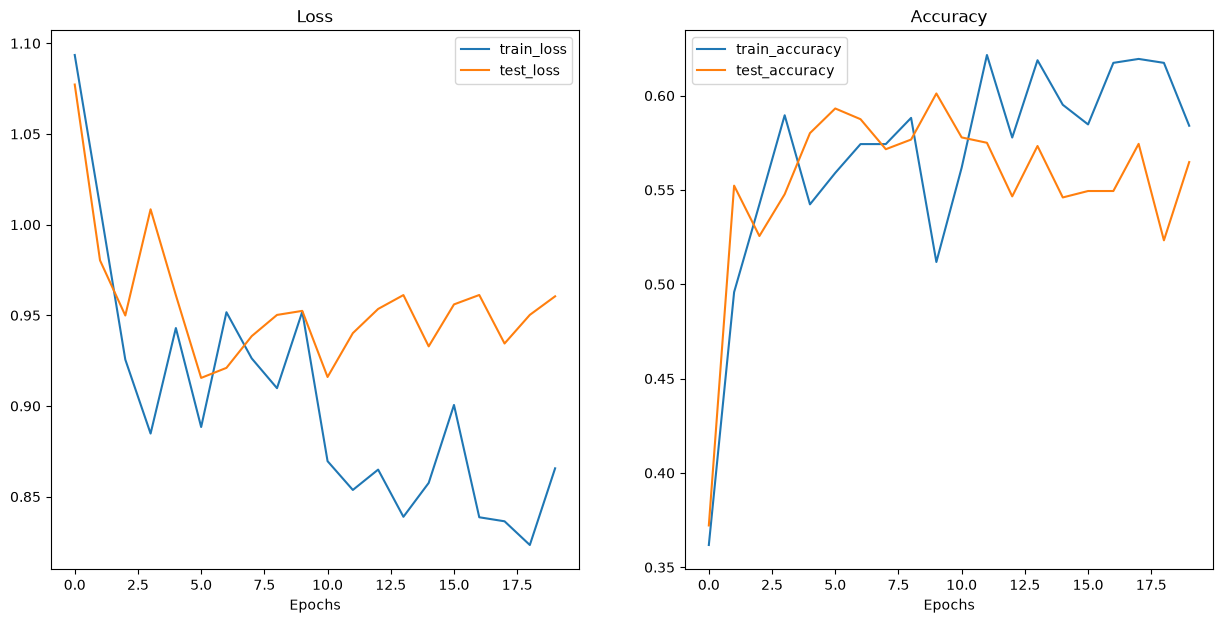

In [184]:
plot_loss_curves(model_0_results)

## 7. Model 1: TinyVGG with Data Augmentation and Adding learning rate decay

In [191]:
# Create training transform with TrivialAugment
train_transform_trivial_augment = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor() 
])

# Create testing transform (no data augmentation)
test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

### 7.1 Create train and test Dataset and Dataloader

In [192]:
# Turn image folders into Datasets
train_data_augmented = datasets.ImageFolder(train_dir, transform=train_transform_trivial_augment)
test_data_simple = datasets.ImageFolder(test_dir, transform=test_transform)

train_data_augmented, test_data_simple

(Dataset ImageFolder
     Number of datapoints: 451
     Root location: data\applepie_fries_icecream_20_percent\train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 150
     Root location: data\applepie_fries_icecream_20_percent\test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                ToTensor()
            ))

In [197]:
train_dir

WindowsPath('data/applepie_fries_icecream_20_percent/train')

In [193]:
# Turn Datasets into DataLoader's
import os
BATCH_SIZE = 32
NUM_WORKERS = 4

torch.manual_seed(21)
train_dataloader_augmented = DataLoader(train_data_augmented, 
                                        batch_size=BATCH_SIZE, 
                                        shuffle=True,
                                        num_workers=NUM_WORKERS)

test_dataloader_simple = DataLoader(test_data_simple, 
                                    batch_size=BATCH_SIZE, 
                                    shuffle=False, 
                                    num_workers=NUM_WORKERS)

train_dataloader_augmented, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x2a290f8ee00>,
 <torch.utils.data.dataloader.DataLoader at 0x2a2d62d7350>)

### 7.3 Construct and train Model 1

In [198]:
# Create model_1 and send it to the target device
torch.manual_seed(21)
model_1 = TinyVGG(
    input_shape=3,
    hidden_units=10,
    output_shape=len(train_data_augmented.classes)).to(device)
model_1

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1690, out_features=3, bias=True)
  )
)

In [195]:
# Set random seeds
torch.manual_seed(21) 
torch.cuda.manual_seed(21)

# Set number of epochs
NUM_EPOCHS = 5

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.001)

# Start the timer
from timeit import default_timer as timer 
start_time = timer()

# Train model_1
model_1_results = train(model=model_1, 
                        train_dataloader=train_dataloader_augmented,
                        test_dataloader=test_dataloader_simple,
                        optimzier=optimizer,
                        loss_fn=loss_fn, 
                        epochs=NUM_EPOCHS)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.1020 | train_acc: 0.3063 | test_loss: 1.0973 | test_acc: 0.2875
Epoch: 2 | train_loss: 1.0870 | train_acc: 0.4382 | test_loss: 1.0621 | test_acc: 0.4813
Epoch: 3 | train_loss: 1.0342 | train_acc: 0.4715 | test_loss: 0.9259 | test_acc: 0.5625
Epoch: 4 | train_loss: 0.9869 | train_acc: 0.5007 | test_loss: 0.9084 | test_acc: 0.5716
Epoch: 5 | train_loss: 0.9657 | train_acc: 0.5437 | test_loss: 0.9307 | test_acc: 0.5330


### 7.4 PLot the loss curves of model 1 

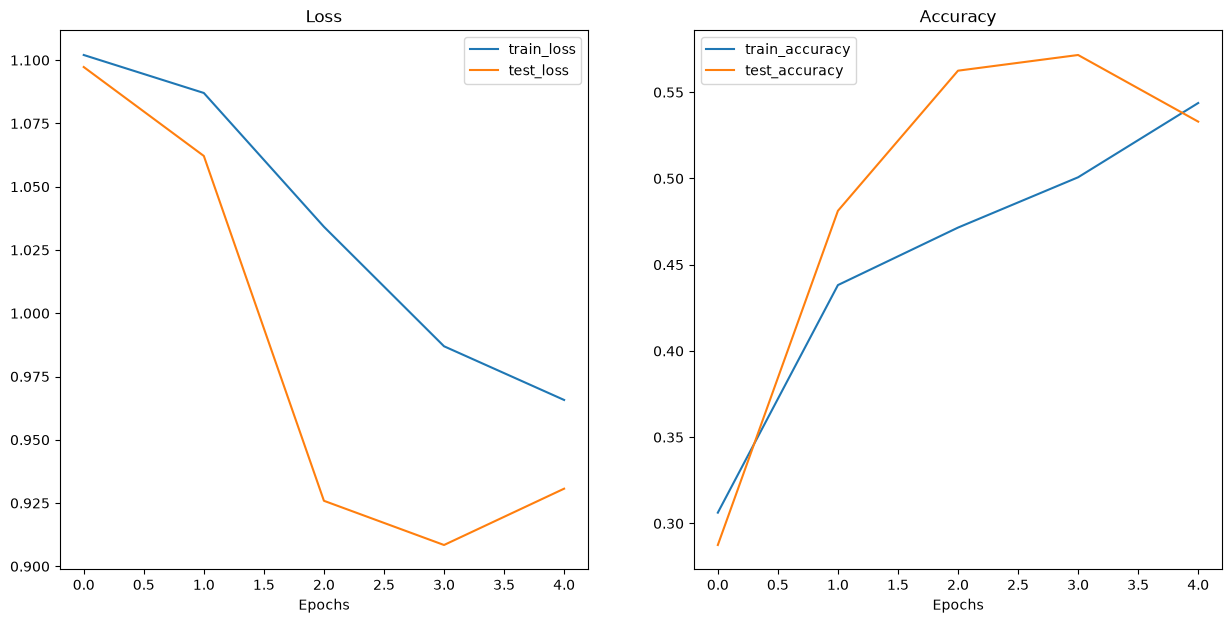

In [199]:
plot_loss_curves(model_1_results)

In [200]:
## 8. Comparing the models
import pandas as pd
model_0_df = pd.DataFrame(model_0_results)
model_1_df = pd.DataFrame(model_1_results)
model_0_df

,train_loss,train_acc,test_loss,test_acc
0,1.093545,0.361806,1.077264,0.372159
1,1.010110,0.495833,0.980303,0.552273
2,0.925592,0.542361,0.949902,0.525568
3,0.884806,0.589583,1.008451,0.547727
4,0.942982,0.542361,0.961078,0.580114
5,0.888409,0.559028,0.915488,0.593182
6,0.951702,0.574306,0.921023,0.587500
7,0.926242,0.574306,0.938523,0.571591
8,0.909826,0.588194,0.950212,0.576705
9,0.951996,0.511806,0.952450,0.601136


In [201]:
model_1_df

,train_loss,train_acc,test_loss,test_acc
0,1.102036,0.306250,1.097280,0.287500
1,1.087030,0.438194,1.062144,0.481250
2,1.034171,0.471528,0.925892,0.562500
3,0.986948,0.500694,0.908427,0.571591
4,0.965736,0.543750,0.930678,0.532955


ValueError: x and y must have same first dimension, but have shapes (20,) and (5,)

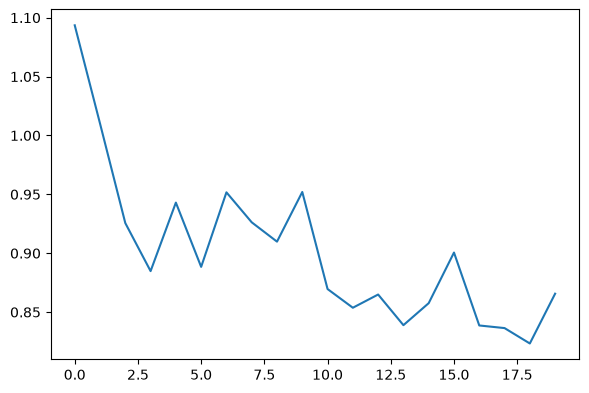

In [202]:
# Setup a plot 
plt.figure(figsize=(15, 10))

# Get number of epochs
epochs = range(len(model_0_df))

# Plot train loss
plt.subplot(2, 2, 1)
plt.plot(epochs, model_0_df["train_loss"], label="Model 0")
plt.plot(epochs, model_1_df["train_loss"], label="Model 1")
plt.title("Train Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot test loss
plt.subplot(2, 2, 2)
plt.plot(epochs, model_0_df["test_loss"], label="Model 0")
plt.plot(epochs, model_1_df["test_loss"], label="Model 1")
plt.title("Test Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot train accuracy
plt.subplot(2, 2, 3)
plt.plot(epochs, model_0_df["train_acc"], label="Model 0")
plt.plot(epochs, model_1_df["train_acc"], label="Model 1")
plt.title("Train Accuracy")
plt.xlabel("Epochs")
plt.legend()

# Plot test accuracy
plt.subplot(2, 2, 4)
plt.plot(epochs, model_0_df["test_acc"], label="Model 0")
plt.plot(epochs, model_1_df["test_acc"], label="Model 1")
plt.title("Test Accuracy")
plt.xlabel("Epochs")
plt.legend();